Cloning into 'Glyphosate'...
Host key verification failed.
fatal: Could not read from remote repository.

Please make sure you have the correct access rights
and the repository exists.
                                           5th    median      95th
Glyphosate (mg/L)                              0.050     0.083     0.136
Cyanobacteria share at peak                    0.653     0.856     0.974
Initial total algal biomass (mg/L)             0.046     0.151     0.493
New cyanobacteria biomass (mg/L)               0.009     0.041     0.156
Peak cyanobacteria biomass (mg/L)              0.038     0.126     0.416
Peak total algal biomass (mg/L)                0.046     0.151     0.493
Baseline detritus (mg/L)                       1.146     2.561     7.738
New bloom detritus (mg/L)                      0.008     0.037     0.141
Total detritus (mg/L)                          1.198     2.612     7.788
Fraction decomposed in 48 h                    0.337     0.419     0.502
Fraction decompose

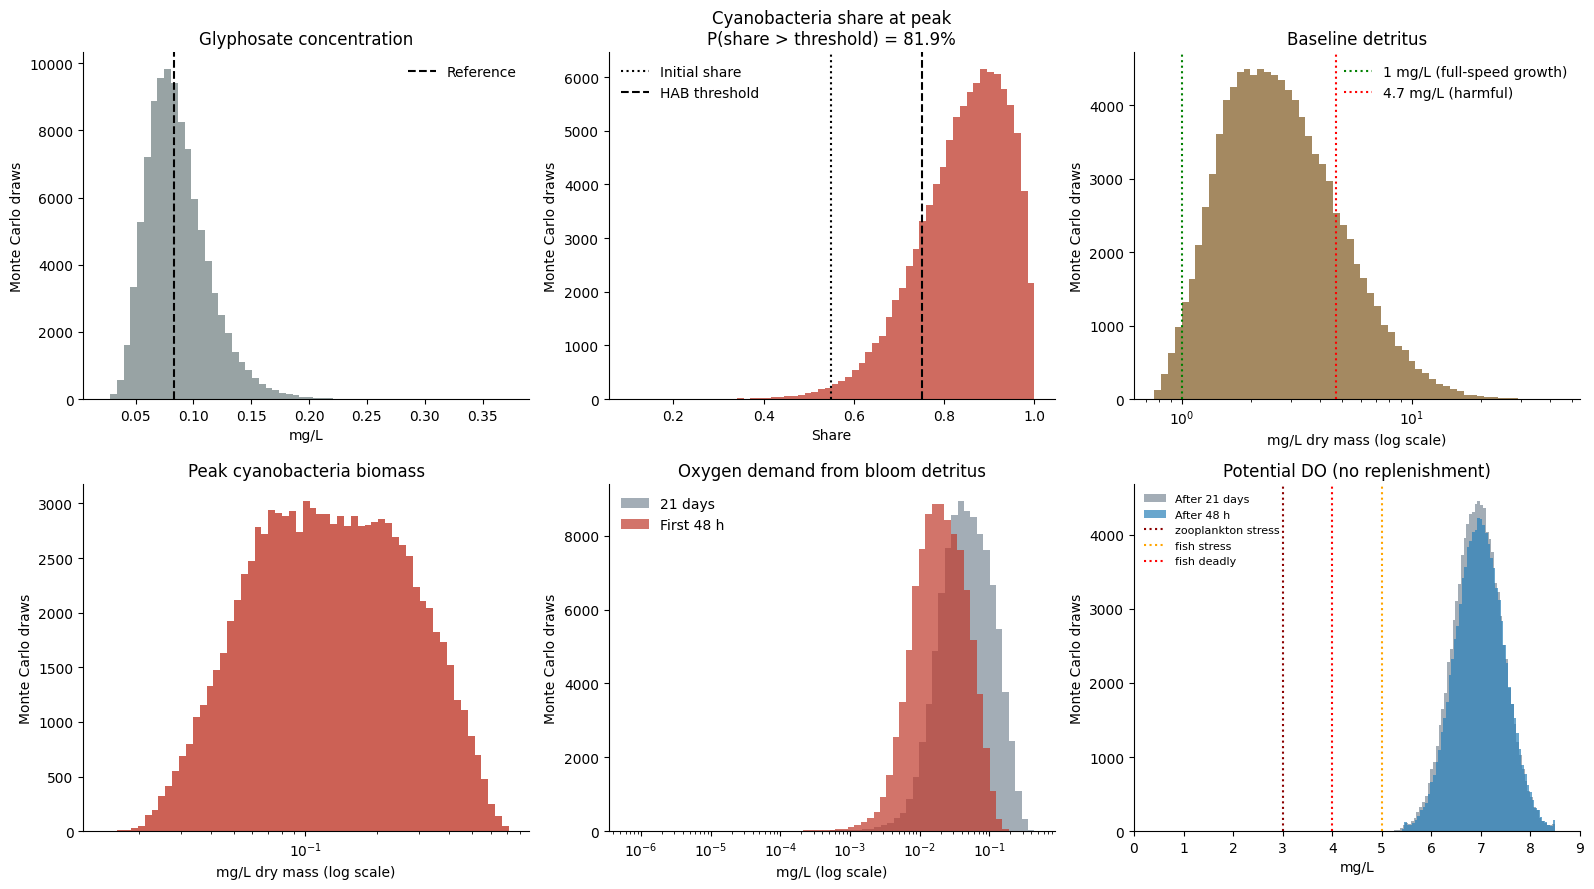

In [ ]:
"""
Simple Monte Carlo: glyphosate -> cyanobacteria growth -> detritus -> dissolved oxygen (DO).

One scenario, with uncertain inputs represented by distributions. Intentionally barebones: no
nutrients, light, mixing, photosynthesis or oxygen replenishment, so "potential DO" is a floor.

Detritus facts used (two different things, not one):
  - More than 80% of the NEW bloom biomass becomes detritus by day 21        -> detritus_frac
  - 41.9% of that detritus decomposes in the first 48 h; the 21-day fraction
    follows from the SAME sampled 48 h value (first-order decay)             -> decomp_48h, decomp_21d

All masses are dry mass in mg/L. DO is dissolved oxygen in mg/L.
"""
!git clone git@github.com:Davido418/Glyphosate.git

import os
import numpy as np
import matplotlib.pyplot as plt

OUT_DIR = os.environ.get("OUT_DIR", "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

N, SEED = 100_000, 42
rng = np.random.default_rng(SEED)

# ---------------- FIXED ASSUMPTIONS ----------------
SHARE0, HAB_SHARE = 0.55, 0.75    # HAB if the cyano share rises 20 points
G_REF, HL_REF = 0.083, 14.0       # mg/L glyphosate and days half-life of the reference case
T_PEAK = 7.0                      # days to bloom peak
T_DECOMP = 21.0                   # days of decomposition counted
EFFECT_MU, EFFECT_SD = np.log(5.19), 0.71   # log-odds effect from the earlier share model
FAST_GROWTH_DETRITUS = 1.0        # mg/L detritus needed for full-speed bloom growth
DETRITUS_HARM = 4.7               # mg/L, scenario threshold

# How is the bloom's new biomass defined?
#   False: total algal mass stays fixed, so the bloom is a shift in share only (default).
#   True:  other algae stay constant and cyanobacteria add mass on top. This fits the
#          study (total biomass rose roughly 10x) and gives a much larger bloom.
TOTAL_MASS_GROWS = False

logit = lambda p: np.log(p / (1 - p))
expit = lambda x: 1 / (1 + np.exp(-np.clip(x, -500, 500)))
loguni = lambda lo, hi: np.exp(rng.uniform(np.log(lo), np.log(hi), N))

# ---------------- UNCERTAIN INPUTS ----------------
glyphosate = rng.lognormal(np.log(0.083), 0.30, N)          # mg/L
half_life = rng.triangular(7, 14, 21, N)                    # days
effect = rng.normal(EFFECT_MU, EFFECT_SD, N)                # log-odds shift in cyano share

# Baseline detritus: suspended sediment (mean ~43 mg/L, truncated to 15-616 mg/L, as provided
# for the Upper Truckee) times a 5-10% detritus fraction. Scenario assumption, not a measurement.
ssc_parts, n_valid = [], 0
while n_valid < N:
    cand = rng.lognormal(np.log(30), 0.7, N)
    keep = cand[(cand >= 15) & (cand <= 616)]
    ssc_parts.append(keep); n_valid += len(keep)
ssc = np.concatenate(ssc_parts)[:N]
detritus0 = ssc * rng.uniform(0.05, 0.10, N)

# Total algal dry mass from chlorophyll-a (0.5-5 ug/L) x dry-mass/chl-a ratio (50-150).
# Reasoned range, not a measured Upper Truckee value; validate against local data.
chl_a = loguni(0.5, 5.0)
algal_mass0 = chl_a * rng.uniform(50, 150, N) / 1000

detritus_frac = rng.uniform(0.80, 1.0, N)                   # share of new bloom that becomes detritus
decomp_48h = np.clip(rng.normal(0.419, 0.05, N), 0.30, 0.55)
o2_yield = rng.uniform(1.0, 1.5, N)                         # mg O2 per mg dry mass decomposed
do0 = np.clip(rng.normal(7.0, 0.5, N), 5.5, 8.5)            # baseline DO

# ---------------- MODEL ----------------
# 1. Glyphosate exposure over the growth window, relative to the reference case
def exposure(g, hl):
    k = np.log(2) / hl
    return g * (1 - np.exp(-k * T_PEAK)) / (k * T_PEAK)
dose_scale = exposure(glyphosate, half_life) / exposure(G_REF, HL_REF)

# 2. Full-speed growth needs baseline detritus >= 1 mg/L; below that the effect is damped
growth_factor = np.minimum(1.0, detritus0 / FAST_GROWTH_DETRITUS)

# 3. Cyanobacteria share at the peak (shift in log-odds, converted back to a proportion)
share_peak = expit(logit(SHARE0) + effect * dose_scale * growth_factor)
hab = share_peak > HAB_SHARE

# 4. Biomass. New cyano biomass comes from the rise in share.
cyano_mass0 = SHARE0 * algal_mass0
other_algae0 = (1 - SHARE0) * algal_mass0
rise = np.maximum(share_peak - SHARE0, 0)
if TOTAL_MASS_GROWS:
    new_cyano_mass = rise * algal_mass0 / (1 - np.minimum(share_peak, 0.99))
    other_algae_peak = other_algae0
else:
    new_cyano_mass = rise * algal_mass0
    other_algae_peak = algal_mass0 - (cyano_mass0 + new_cyano_mass)   # others shrink, total fixed
cyano_mass_peak = cyano_mass0 + new_cyano_mass
algal_mass_peak = cyano_mass_peak + other_algae_peak

# 5. New bloom biomass becomes detritus
bloom_detritus = detritus_frac * new_cyano_mass
total_detritus = detritus0 + bloom_detritus

# 6. One first-order decomposition process: 21-day fraction derived from the same 48 h draw
decomp_21d = 1 - (1 - decomp_48h) ** (T_DECOMP / 2)

# 7. Oxygen demand and potential DO (no replenishment)
demand_48h = o2_yield * decomp_48h * bloom_detritus
demand_21d = o2_yield * decomp_21d * bloom_detritus
do_48h = np.maximum(do0 - demand_48h, 0)
do_21d = np.maximum(do0 - demand_21d, 0)

# ---------------- RESULTS ----------------
p = lambda x: np.percentile(x, [5, 50, 95])
def row(name, x): print(f"{name:42s}" + "".join(f"{v:10.3f}" for v in p(x)))

print("                                           5th    median      95th")
row("Glyphosate (mg/L)", glyphosate)
row("Cyanobacteria share at peak", share_peak)
row("Initial total algal biomass (mg/L)", algal_mass0)
row("New cyanobacteria biomass (mg/L)", new_cyano_mass)
row("Peak cyanobacteria biomass (mg/L)", cyano_mass_peak)
row("Peak total algal biomass (mg/L)", algal_mass_peak)
row("Baseline detritus (mg/L)", detritus0)
row("New bloom detritus (mg/L)", bloom_detritus)
row("Total detritus (mg/L)", total_detritus)
row("Fraction decomposed in 48 h", decomp_48h)
row("Fraction decomposed by day 21", decomp_21d)
row("Oxygen demand, first 48 h (mg/L)", demand_48h)
row("Oxygen demand, 21 days (mg/L)", demand_21d)
row("Potential DO after 48 h (mg/L)", do_48h)
row("Potential DO after 21 days (mg/L)", do_21d)

print(f"\nTOTAL_MASS_GROWS = {TOTAL_MASS_GROWS}")
print(f"P(cyano share > {HAB_SHARE}): {hab.mean():.1%}")
print(f"P(baseline detritus >= {FAST_GROWTH_DETRITUS} mg/L, full-speed growth): {(detritus0 >= FAST_GROWTH_DETRITUS).mean():.1%}")
print(f"P(total detritus > {DETRITUS_HARM} mg/L): {(total_detritus > DETRITUS_HARM).mean():.1%}")
print("\nP(potential DO below ...)            48 h    21 days")
for t, lab in [(5, "fish stress"), (4, "deadly"), (3, "zooplankton stress"), (2, "fish fatal range"), (1, "zooplankton death")]:
    print(f"  {t} mg/L ({lab:18s}) {(do_48h < t).mean():8.2%} {(do_21d < t).mean():9.2%}")
print(f"  DO reaches zero               {(do_21d <= 0).mean():8.2%}")

rank = lambda x: np.argsort(np.argsort(x))
spearman = lambda x, y: np.corrcoef(rank(x), rank(y))[0, 1]
drivers = dict(algal_mass0=algal_mass0, cyano_effect=effect, glyphosate=glyphosate, half_life=half_life,
               baseline_detritus=detritus0, baseline_DO=do0, o2_yield=o2_yield,
               decomp_48h=decomp_48h, detritus_frac=detritus_frac)
print("\nDrivers of 21-day oxygen demand (Spearman correlation):")
for k, v in sorted(drivers.items(), key=lambda kv: -abs(spearman(kv[1], demand_21d))):
    print(f"  {k:20s}{spearman(v, demand_21d):+.2f}")

# ---------------- FIGURE ----------------
def loghist(ax, x, **kw):
    x = x[x > 0]
    if len(x) == 0: return
    lo, hi = x.min(), max(x.max(), x.min() * 1.01)
    ax.hist(x, bins=np.logspace(np.log10(lo), np.log10(hi), 60), **kw); ax.set_xscale("log")

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
a = ax[0, 0]; a.hist(glyphosate, bins=60, color="#7f8c8d", alpha=0.8)
a.axvline(0.083, color="k", ls="--", label="Reference"); a.set_title("Glyphosate concentration")
a.set_xlabel("mg/L"); a.legend(frameon=False)

a = ax[0, 1]; a.hist(share_peak, bins=60, color="#c0392b", alpha=0.75)
a.axvline(SHARE0, color="k", ls=":", label="Initial share"); a.axvline(HAB_SHARE, color="k", ls="--", label="HAB threshold")
a.set_title(f"Cyanobacteria share at peak\nP(share > threshold) = {hab.mean():.1%}"); a.set_xlabel("Share"); a.legend(frameon=False)

a = ax[0, 2]; loghist(a, detritus0, color="#8e6c3a", alpha=0.8)
a.axvline(FAST_GROWTH_DETRITUS, color="green", ls=":", label="1 mg/L (full-speed growth)")
a.axvline(DETRITUS_HARM, color="red", ls=":", label="4.7 mg/L (harmful)")
a.set_title("Baseline detritus"); a.set_xlabel("mg/L dry mass (log scale)"); a.legend(frameon=False)

a = ax[1, 0]; loghist(a, cyano_mass_peak, color="#c0392b", alpha=0.8)
a.set_title("Peak cyanobacteria biomass"); a.set_xlabel("mg/L dry mass (log scale)")

a = ax[1, 1]
loghist(a, demand_21d, color="#34495e", alpha=0.45, label="21 days")
loghist(a, demand_48h, color="#c0392b", alpha=0.7, label="First 48 h")
a.set_title("Oxygen demand from bloom detritus"); a.set_xlabel("mg/L (log scale)"); a.legend(frameon=False)

a = ax[1, 2]
a.hist(do_21d, bins=60, color="#34495e", alpha=0.45, label="After 21 days")
a.hist(do_48h, bins=60, color="#2980b9", alpha=0.7, label="After 48 h")
for t, c, lab in [(3, "darkred", "zooplankton stress"), (5, "orange", "fish stress"), (4, "red", "fish deadly")]:
    a.axvline(t, color=c, ls=":", label=lab)
a.set_xlim(0, 9); a.set_title("Potential DO (no replenishment)"); a.set_xlabel("mg/L"); a.legend(frameon=False, fontsize=8, loc="upper left")

for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False); a.set_ylabel("Monte Carlo draws")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "do_loss_simple_v2.png"), dpi=200)
plt.show()